# Trust Before Pass
## An evidence-driven investigation of power-on reset

**秦睿遥 · Fudan University · QuRYous111**  
Code-a-Chip ISSCC 2027 · submission revision of v0.5

**Your job:** decide which conclusions a waveform supports before trusting a reported delay.
A completed simulation can contain an undefined measurement. That same record can also violate
an explicitly declared functional requirement. Those are separate questions.

You will follow a public SKY130 POR through normal startup, a historical dependency anomaly,
controlled experiments, automated checks and an independent challenge.

**Evidence labels:** all default waveform displays are **recorded SPICE data**. Parameter changes
reassess those data; they do not simulate new circuits or model conditions. Software fixtures
are explicitly synthetic. The optional live CACE path is separate.

**Limits visible from the start:** one circuit; mostly one nominal PVT; two ramps; known upstream
HVL correction, not our circuit fix. The new functional requirement T1 is a teaching assumption,
not a proven original design specification. No human learning outcome has yet been established.

### Choose a learning depth

| Layer | What you will be able to do | Evidence of mastery |
|---|---|---|
| Basic · Acts 1–3 | Explain POR assertion and distinguish an absent event from a delayed event | Predict a window experiment and cite a waveform observation |
| Advanced · Acts 4–6 | Choose a controlled comparison and separate measurement from functional compliance | Explain a rejected hypothesis and solve a held-out observation problem |
| Engineering · Act 7 | Define a sourced check and use it outside this notebook | Write a contract, name its unsupported cases, and run its test |

The browser learning route needs no Python or EDA installation. Executing the optional engineering Notebook requires Python and the listed free packages, with no PDK or EDA executable. Run that Notebook from this directory. Read one act at a time. Open the linked offline experiment desk for labelled controls; no code editing or kernel is
needed to use that page. Run All initializes this Notebook without inventing learner answers.
Static readers can complete paper-based tasks using the script-free worksheet.

**Start without programming:** extract the package and open
[`START_HERE.html`](START_HERE.html). It explains the signals and both timing definitions before linking to the experiments. The four tasks use ordinary form controls,
real recorded waveform images and explanatory feedback. A standalone browser is sufficient.
The [static worksheet](STATIC_WORKBOOK.html) works with scripts disabled. Read this Notebook
or its HTML export for the seven-act narrative and optional engineering details.

In [1]:
from pathlib import Path
import json, os
os.environ.update(OMP_NUM_THREADS='1', OPENBLAS_NUM_THREADS='1', MKL_NUM_THREADS='1')
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import display, Image, Markdown
from evidence import verify_manifest, assess_run, Contract
from functional import FunctionalContract
from lesson import Investigation, experiment, plot_cases, explain, hypothesis_feedback, CASES
ROOT = Path.cwd()
print('Evidence files checked:', verify_manifest(ROOT))
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False,
                     'axes.spines.right':False, 'font.size':10})
def show(fig):
    b=BytesIO(); fig.savefig(b,format='png',dpi=140,bbox_inches='tight')
    display(Image(data=b.getvalue())); plt.close(fig)
def table(headers, rows):
    display(Markdown('| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'+
        '\n'.join('| '+' | '.join(str(v) for v in row)+' |' for row in rows)))
journal = Investigation()
print('Replay only. Learner journal stays in memory until you explicitly save it.')

Evidence files checked: 373
Replay only. Learner journal stays in memory until you explicitly save it.


## Act 1 · Normal startup — what does a POR do?

**Why:** interpreting a delay requires knowing what each event means.  
**Task:** point to supply rise, oscillator activity and reset assertion, in that order; explain
why POR rising is not reset release. **Mastery check:** identify which part of the reset sequence
is not covered by a 4 ms observation.

The public design monitors AVDD against a selectable nominal 2.4–3.0 V trip point. A roughly
1 ms one-shot then precedes an active-high `por` reset pulse; a second timer gives a nominal
50 ms assertion window. Our short startup record does not measure that entire pulse.
The oscillator times the digital control, while the analog comparator enable links the
power-monitoring circuitry to that control. The diagram below is an **explanatory block diagram**,
not a transistor schematic or simulated signal.

Source: pinned [upstream README](assets/por/README.upstream.md). Trace: corrected HVL, nonlinear
resistor model, tt / 27 °C, AVDD 0→3.3 V in 2 ms, DVDD 1.8 V.

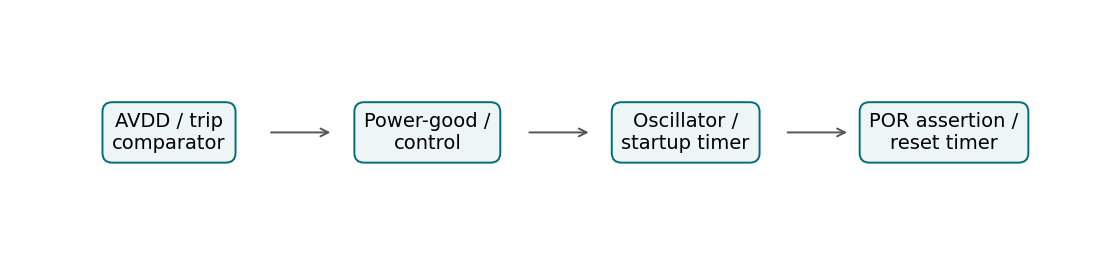

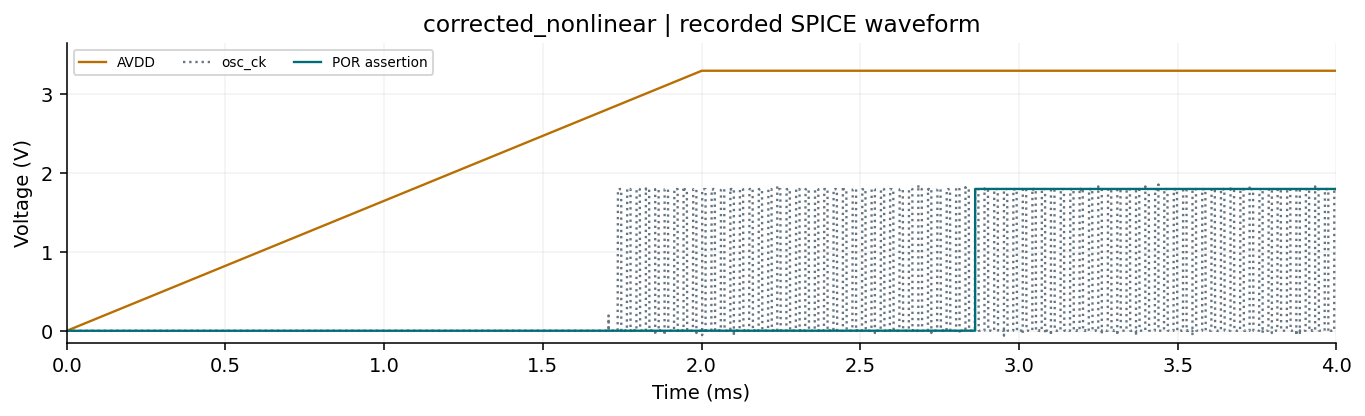

In [2]:
fig,ax=plt.subplots(figsize=(10,2.2))
for x,text in [(0,'AVDD / trip\ncomparator'),(1,'Power-good /\ncontrol'),(2,'Oscillator /\nstartup timer'),(3,'POR assertion /\nreset timer')]:
    ax.text(x,0,text,ha='center',va='center',bbox=dict(boxstyle='round,pad=.5',fc='#edf5f5',ec='#006d77'))
    if x<3: ax.annotate('',xy=(x+.64,0),xytext=(x+.38,0),arrowprops={'arrowstyle':'->','color':'#555'})
ax.set(xlim=(-.6,3.6),ylim=(-.7,.7));ax.axis('off');show(fig)
show(plot_cases(['corrected_nonlinear']))

## Act 2 · An anomalous delay — is the number meaningful?

**Why:** checking only a numeric bound can hide how a number was obtained.  
**Task:** compare this recorded old-HVL waveform with Act 1 and decide whether a startup delay
defined by two rises **after 1.5 ms** can be measured. **Mastery check:** name the missing prerequisite.

The original testbench chooses the first oscillator and POR rises after 1.5 ms, at 0.9 V.
Its scalar bound is 0.5–2 ms. The archived simulator may still emit a number after a required
`.meas` fails. Inspect both the number and the log; the number alone is not an oracle.
Stock CACE already flags the negative scalar as a failure. We do not claim discovery of a
fault that CACE's numeric comparison missed.

Recorded export: 2.95567E-05
-0.00150328
Relevant recorded log lines:
Error: measure  por_start  when(WHEN) : out of interval
 meas tran por_start when v(por)=9.000000e-01 td=1.5m rise=1 failed!
Error: &por_start: no such variable.


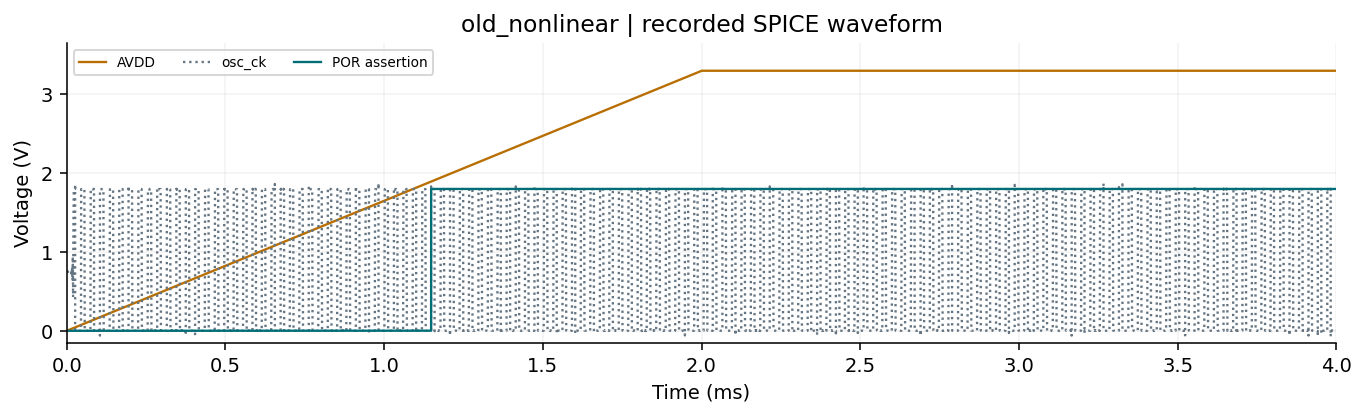

In [3]:
from lesson import load_case
a,old_path=load_case('old_nonlinear')
print('Recorded export:', (old_path/'response_0.data').read_text().strip())
print('Relevant recorded log lines:')
log=(old_path/'stdout.log').read_text(errors='replace')
print('\n'.join(x for x in log.splitlines() if 'por_start' in x or 'no such variable' in x))
show(plot_cases(['old_nonlinear']))

## Act 3 · Predict, choose a window, then investigate

**Why:** failure to see an event can mean different things depending on the observed history.  
**Task W:** predict the measurement and functional results when only 2.5 ms of the old-HVL
record is visible. Then repeat with 4.0 ms. **Mastery check:** explain why changing observation
duration changes what can be concluded without changing the recorded simulator execution.

For this exercise we introduce **T1, an explicit teaching assumption**: after AVDD rises through
3.0 V, a **new** POR rise through 0.9 V must occur within 2 ms, while AVDD stays above 3.0 V.
The deadline is relative to the observed supply trigger, not absolute simulation time.
An earlier POR high level does not count as that new edge. This is not the upstream oscillator
delay definition. Read [the contract and limits](FUNCTIONAL_CONTRACT.md).

Use the **Observation window** controls in the experiment desk. Choose an end time, then record a prediction and reason before opening evidence. Gray space contains **unobserved** data; no future waveform is shown there.

### Observation window: use the controls

Open the [offline experiment desk](INVESTIGATION_DESK.html?task=window) in a browser.
Use dropdowns to choose conditions and predictions, enter your reason, and press
**Record prediction & open evidence**. Then explain your observation and request feedback.
No Python editing is needed. A changed condition starts a new prediction; earlier experiments
stay in the local journal until you close the page. Use **Download readable notes (.txt)** to keep them.

If this Notebook viewer blocks embedded pages, open `INVESTIGATION_DESK.html` directly from
the extracted folder. If scripts are disabled, use the [static worksheet](STATIC_WORKBOOK.html).
All browser choices are finite Python-precomputed checks of real recorded SPICE data, not new simulations.

In [4]:
from IPython.display import IFrame
display(IFrame('INVESTIGATION_DESK.html?task=window', width='100%', height=950))

### Choose a hypothesis before seeing the controlled comparisons

Could the anomaly come from initialization, the resistor representation, the HVL dependency,
or the selected measurement window? Multiple hypotheses can sound plausible. Choose an
experiment that distinguishes them instead of changing several variables together.

**Task H:** choose one hypothesis and record what result would falsify it. Use the named choices in the controls: supply initialization, resistor representation, model library, or measurement window.
The hypothesis controls supply the matched evidence; explain your observation before revealing feedback.

### Hypothesis and model comparison: use the controls

Open the [offline experiment desk](INVESTIGATION_DESK.html?task=model) in a browser.
Use dropdowns to choose conditions and predictions, enter your reason, and press
**Record prediction & open evidence**. Then explain your observation and request feedback.
No Python editing is needed. A changed condition starts a new prediction; earlier experiments
stay in the local journal until you close the page. Use **Download readable notes (.txt)** to keep them.

If this Notebook viewer blocks embedded pages, open `INVESTIGATION_DESK.html` directly from
the extracted folder. If scripts are disabled, use the [static worksheet](STATIC_WORKBOOK.html).
All browser choices are finite Python-precomputed checks of real recorded SPICE data, not new simulations.

## Act 4 · Control one change, follow its effect

**Why:** a faster or different simulation is not necessarily a valid repair.  
**Task M:** choose a resistor model and predict the effect of changing only the recorded HVL
dependency. **Mastery check:** explain what the matched comparison supports and what it cannot
establish about the original designer's environment.

The archived 2×2 comparison uses old/corrected HVL with nonlinear/simplified resistors. Select the named resistor model in the experiment desk. These are discrete recorded experiments, not interpolated model
settings. The linear model is a documented intervention; it is not needed for the corrected
nonlinear baseline. Internal comparator-enable probes are available for the linear pair.

The HVL correction is an **existing upstream fix from July 2023**. We initially reconstructed
the experiment with an older dependency. Credit belongs to the upstream authors, not this
notebook. Only the two used level-shifter bodies change; three used inverter bodies match
after whitespace normalization. Neither this comparison nor the checker automatically
diagnoses arbitrary circuit faults.

### A useful negative result

Removing the explicit AVDD DC override alone did not restore the required POR event. This
rejects that intervention as a sufficient repair in these runs; it does not rule out every
initialization effect. The two traces below share the original nonlinear model setup and
differ in that DC override. They are separate from the later 1e-9 current-tolerance 2×2 set.
Do not attribute effects across unmatched experiments to a single parameter.

[Known HVL correction](https://github.com/fossi-foundation/skywater-pdk-libs-sky130_fd_sc_hvl/commit/c02b604487951837e42947ce87475bb62549d9e3).
Each deck, model revision, log and resource record is under `data/runs/` and `NOTICE`.

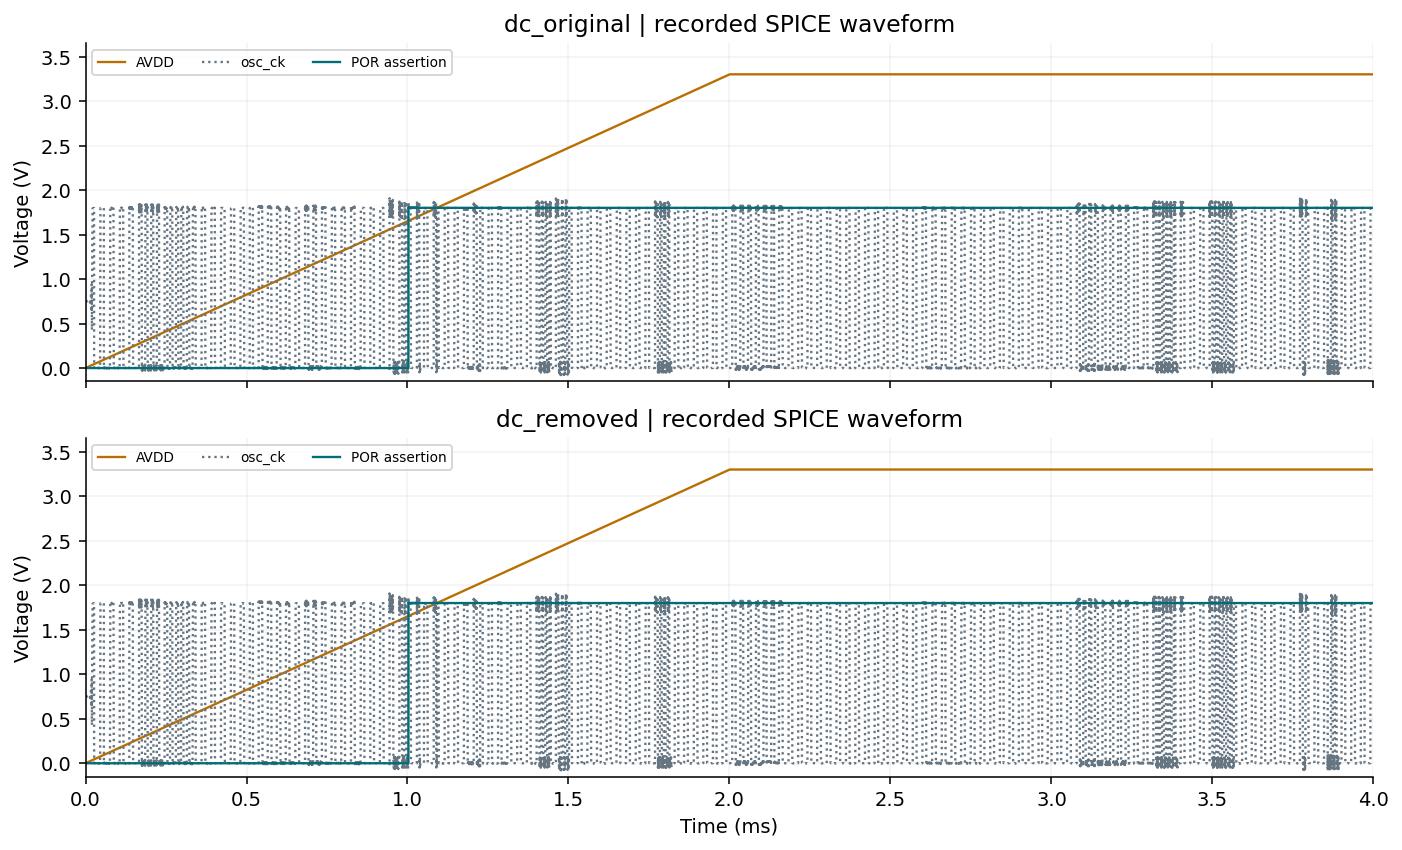

In [5]:
show(plot_cases(['dc_original','dc_removed']))

## Act 5 · Automate the questions without merging them

**Why:** a useful checker explains both what failed and what cannot yet be assessed.  
**Task R:** tighten only the scalar upper bound from 2 ms to 1 ms on the corrected record.
Predict which judgment changes. **Mastery check:** explain why the function result should not
be derived from the scalar result.

| Dimension | Question | Example outcomes |
|---|---|---|
| Execution | Did the recorded process complete? | COMPLETE / ERROR / INCOMPLETE |
| Measurement | Can these required events support this delay? | VALID / INVALID / UNAVAILABLE |
| Scalar specification | Is a valid delay inside its numerical bounds? | PASS / FAIL / NOT_EVALUATED |
| Function under T1 | Was the declared post-supply response witnessed by its deadline? | PASS / FAIL / NOT_TRIGGERED / INSUFFICIENT_EVIDENCE |

`NOT_TRIGGERED` is not a vacuous pass. An incomplete observation cannot establish that a
deadline was missed. Conversely, a fully observed missing response can produce both an
invalid delay **and** a functional failure under T1.

The browser controls change event extraction or numerical delay bounds. T1 keeps a fixed 2 ms deadline; only the optional Python API supports changing that deadline.
They do not modify the circuit and do not reinterpret the historical `.meas` export under a
different rule. The original log/scalar cross-check is retained in `archive_audit`.

### Measurement rules: use the controls

Open the [offline experiment desk](INVESTIGATION_DESK.html?task=rules) in a browser.
Use dropdowns to choose conditions and predictions, enter your reason, and press
**Record prediction & open evidence**. Then explain your observation and request feedback.
No Python editing is needed. A changed condition starts a new prediction; earlier experiments
stay in the local journal until you close the page. Use **Download readable notes (.txt)** to keep them.

If this Notebook viewer blocks embedded pages, open `INVESTIGATION_DESK.html` directly from
the extracted folder. If scripts are disabled, use the [static worksheet](STATIC_WORKBOOK.html).
All browser choices are finite Python-precomputed checks of real recorded SPICE data, not new simulations.

### Compare with a simpler solution

A small Python script can answer the same questions on these supported cases. This project
does not establish a better detection rate. The proposed value is explicit contracts, evidence
links, guarded experiment steps and a reusable workflow. If you only need a single known check,
the simple script may be sufficient.

The table below presents four matched recorded cases; the slow-supply case is held back for
your challenge. The saved benchmark also covers it, but do not open its results before Act 6.
These are not independent defects. Native CACE's numerical evaluator is compared separately because it
does not implement T1. `data/cace_baseline.json` contains the earlier actual pinned CACE evaluator
results; complete CLI evidence is under `data/cace_integration/`.
See [baseline scope and costs](BASELINE_COMPARISON.md).

In [6]:
baseline=json.loads((ROOT/'data/v03_baseline.json').read_text())
table(['Recorded case','Simple Python measurement','Simple Python scalar','Simple Python T1','Our T1'],
      [[r['case'],r['baseline']['measurement'],r['baseline']['scalar_spec'],r['baseline']['functional'],r['tool_functional']]
       for r in baseline['rows'] if r['case']!='slow_supply'])
print(baseline['result'])
native=json.loads((ROOT/'data/cace_baseline.json').read_text())
table(['Recorded case','Native CACE numeric evaluator'],
      [[r['run_id'],r['cace_status']] for r in native['results'] if r['run_id'] in
       ('tt27_continuous_nanoamp','tt27_continuous_fossi')])

| Recorded case | Simple Python measurement | Simple Python scalar | Simple Python T1 | Our T1 |
| --- | --- | --- | --- | --- |
| old_nonlinear | INVALID | NOT_EVALUATED | FAIL | FAIL |
| corrected_nonlinear | VALID | PASS | PASS | PASS |
| old_linear | INVALID | NOT_EVALUATED | FAIL | FAIL |
| corrected_linear | VALID | PASS | PASS | PASS |

All categorical results agree on the supported domain. No detection superiority demonstrated.


| Recorded case | Native CACE numeric evaluator |
| --- | --- |
| tt27_continuous_nanoamp | FAILURE |
| tt27_continuous_fossi | SUCCESS |

## Act 6 · Independent challenge — what evidence would you request next?

**Why:** recognizing a familiar answer is weaker than making a new judgment.  
**Task C:** a second record has a 4 ms supply ramp. You have only its first **4.4 ms**.
Using the same T1 rule, decide: can the selected oscillator-to-POR delay be calculated; can
functional success or failure be established; which next observation would discriminate the
possibilities? **Mastery check:** write your reason and design one assertion for a checker.

This is a held-out **observation scenario from a real recorded simulation**, not a new physical
defect and not a synthetic trace. The unobserved future is hidden. Make your initial judgment
before requesting more time. Do not open the facilitator key during the task.

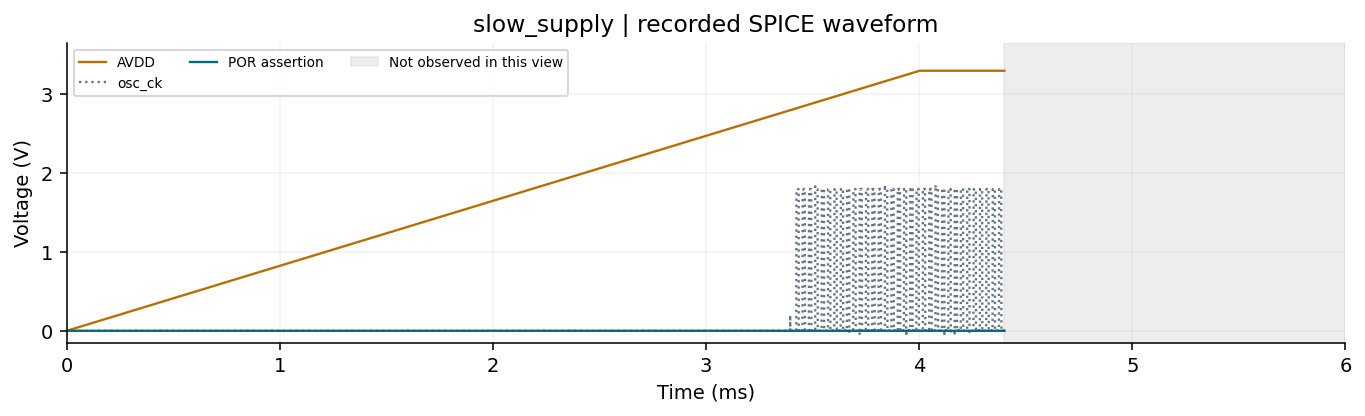

In [7]:
show(plot_cases(['slow_supply'],observe_until_ms=4.4))

### Independent challenge: use the controls

Open the [offline experiment desk](INVESTIGATION_DESK.html?task=challenge) in a browser.
Use dropdowns to choose conditions and predictions, enter your reason, and press
**Record prediction & open evidence**. Then explain your observation and request feedback.
No Python editing is needed. A changed condition starts a new prediction; earlier experiments
stay in the local journal until you close the page. Use **Download readable notes (.txt)** to keep them.

If this Notebook viewer blocks embedded pages, open `INVESTIGATION_DESK.html` directly from
the extracted folder. If scripts are disabled, use the [static worksheet](STATIC_WORKBOOK.html).
All browser choices are finite Python-precomputed checks of real recorded SPICE data, not new simulations.

## Act 7 · Transfer the method into an engineering workflow

**Why:** the check should remain usable after the lesson ends.  
**Task E:** propose a check for another measured delay. Name its trigger, response, deadline,
observation requirements, specification source and at least one case where it must abstain.
**Mastery check:** distinguish a sourced engineering requirement from a teaching assumption.

The independent API below is an optional engineering example; novice readers can use the browser controls without editing it. It consumes recorded artifacts. `functional.py` can also consume arrays
directly. Its tests include analytically specified synthetic signals and separately labeled
real-record regressions. The existing CACE hook checks waveform prerequisites through the
normal script interface. Its Error output is **not** the T1 functional verdict; the sidecar API
provides the independent judgment. We have not patched CACE's core or overloaded its status enum.

Prior complete CACE runs used unmodified pinned CACE → real xschem → ngspice → script hook →
summary/exit status, with byte-identical saved waveforms. They used a SPICE-body schematic wrapper,
not a reconstructed transistor schematic or layout flow. New release verification distinguishes
replayed historical integration evidence from any newly executed runs.

In [8]:
r=assess_run(ROOT/'data/runs/tt27_continuous_nanoamp',functional_contract=FunctionalContract())
table(['Execution','Measurement','Scalar specification','Function under T1'],
      [[r['execution'],r['measurement'],r['scalar_spec'],r['functional']['status']]])
print('Functional evidence:',r['functional']['reason'])
print('Specification source:',r['functional']['contract']['source'])

| Execution | Measurement | Scalar specification | Function under T1 |
| --- | --- | --- | --- |
| COMPLETE | INVALID | NOT_EVALUATED | FAIL |

Functional evidence: deadline_observed_without_new_por_rise; an earlier high level is not a new edge
Specification source: Teaching assumption T1; FUNCTIONAL_CONTRACT.md, not an upstream acceptance specification


<details><summary>Engineering layer: optional live simulation and source inspection</summary>

Use `python cace_project.py --help` and `CACE_INTEGRATION.md` for the full CLI. The runner requires
local xschem, XSPICE-enabled ngspice and CACE. It installs nothing, uses one worker, records peak
process-tree memory and terminates on declared time/memory/output budgets. Existing complete-flow
measurements peaked near 587 MiB on this host; that is not a full-EDA memory estimate.

Core replay needs no external executable. For a fresh simulation, inspect the command, choose a
short writable output path, and run it deliberately. Label the resulting data fresh SPICE and
retain the command, dependencies and resource record. Do not mix it into an archived-case selector.

Read `evidence.py`, `functional.py`, `simple_baseline.py` and `test_functional.py`. A broader temporal
specification may justify an existing tool such as RTAMT; this narrow monitor is not a replacement
for a temporal-logic engine. CACE already provides characterization and script hooks.

</details>

### Keep a record of your investigation

Use the experiment desk’s **Download readable notes (.txt)** button to save your attempts locally. Nothing is uploaded. The page keeps answers in memory only; export before closing it. The reader study has
not yet taken place. A successfully executed notebook or automated journal test is not evidence
that a learner completed the tasks.

### Evidence, attribution and remaining work

- Original POR: ajcci repository, commit `db8745ef4d7d85a1852fc60c251ba34c6cebe497`.
- Corrected HVL: FOSSi commit `e5413e01fa071029ba84d9faa98d9acd80e75a38`; existing correction credited above.
- CACE: `dedb5e0d30f5c286d36a1511b61fc81795bd24cf`; full dependency pins in `NOTICE` and provenance files.
- Real records: `data/runs/`; original published result archives: `data/published/`; model and recipe hashes: `MANIFEST.json`.
- Source for upstream behavior: `assets/por/README.upstream.md`. Original event extraction: `assets/por/response_time.original.spice`.
- Reader tasks and evaluation protocol: `reader/READER_GUIDE.md` and `reader/FACILITATOR.md`.

The original archives contain 161 passing scalars across 18 groups, with one old startup group
missing a declared PVT point; its cause is unknown. Available passing samples do not establish
complete coverage. Neither the new function contract nor this teaching investigation fills that gap.

We contribute a reproducible investigation, a narrow independent monitor, and reusable teaching
controls. We do not claim a new POR defect, new upstream repair, general automatic diagnosis,
better accuracy than a simple script, measured learning improvement, or paper-level novelty.
Independent reader evaluation and feedback-driven revision remain future work. Brownout recovery,
full reset pulse validation, broad PVT, silicon correlation and a second circuit remain future work.

Apache-2.0; upstream model headers and licenses retained. AI assistance was used in research,
implementation and drafting. The named author must review and understand the work. Code-a-Chip
is a travel-support/poster opportunity, not ISSCC technical-paper acceptance.